# 📊 GridForecast — 02: Baselines

**Цел:** Дефиниране на baseline модели за 24-часов forecasting.

**Baselines:**
1. Naive (persistence) — `y[t] = y[t-1]`
2. Seasonal Naive (24h) — `y[t] = y[t-24]`
3. Weekly Naive (168h) — `y[t] = y[t-168]`
4. Linear Regression с календарни features

**Метрики:** MAE, RMSE, MAPE

**Допълнително:**
- Time Series Cross-Validation
- Residuals анализ
- Грешки по час и ден от седмицата
- Сравнение на 4 drift сценария

## 1️⃣ Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.graphics.tsaplots import plot_acf

from gridforecast.config import (
    SYNTHETIC_DIR,
    FIGURES_DIR,
    DRIFT_TYPES,
    FORECAST_HORIZON_HOURS,
    TRAIN_RATIO,
    RANDOM_SEED,
)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(RANDOM_SEED)

print("✅ Imports OK")
print(f"   Horizon: {FORECAST_HORIZON_HOURS}h")
print(f"   Train ratio: {TRAIN_RATIO}")

✅ Imports OK
   Horizon: 24h
   Train ratio: 0.8


## 2️⃣ Load stable dataset

In [2]:
df = pd.read_parquet(SYNTHETIC_DIR / "consumption_stable.parquet")
df.index = pd.DatetimeIndex(df.index)

print(f"Rows:  {len(df):,}")
print(f"Range: {df.index[0]} → {df.index[-1]}")
print(f"Mean:  {df['consumption_mw'].mean():.1f} MW")
df.head()

Rows:  17,520
Range: 2023-01-01 00:00:00 → 2024-12-30 23:00:00
Mean:  1128.6 MW


,consumption_mw,temperature_c,is_holiday,is_weekend,hour,day_of_week,day_of_year,month,drift_factor
timestamp,,,,,,,,,
2023-01-01 00:00:00,971.407629,-0.617696,True,True,0,6,1,1,1.0
2023-01-01 01:00:00,1023.915710,-4.101691,True,True,1,6,1,1,1.0
2023-01-01 02:00:00,972.499609,-1.020323,True,True,2,6,1,1,1.0
2023-01-01 03:00:00,971.443062,-0.810467,True,True,3,6,1,1,1.0
2023-01-01 04:00:00,1092.938705,-6.423295,True,True,4,6,1,1,1.0


## 3️⃣ Train / test split (time-based, 80/20)

⚠️ **ВАЖНО:** Никога random split за time series! Само time-based.

In [3]:
split_idx = int(TRAIN_RATIO * len(df))
train = df.iloc[:split_idx]
test = df.iloc[split_idx:]

print(f"Train: {len(train):,} rows | {train.index[0]} → {train.index[-1]}")
print(f"Test:  {len(test):,} rows | {test.index[0]} → {test.index[-1]}")
print(f"\nTrain mean: {train['consumption_mw'].mean():.1f} MW")
print(f"Test mean:  {test['consumption_mw'].mean():.1f} MW")

Train: 14,016 rows | 2023-01-01 00:00:00 → 2024-08-06 23:00:00
Test:  3,504 rows | 2024-08-07 00:00:00 → 2024-12-30 23:00:00

Train mean: 1157.5 MW
Test mean:  1013.3 MW


## 4️⃣ Helper: metrics

In [4]:
def mape(y_true, y_pred):
    """Mean Absolute Percentage Error (%)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


def evaluate(y_true, y_pred, name):
    return {
        "model": name,
        "MAE":  mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE": mape(y_true, y_pred),
    }


# Helper за Naive predictions (safe за всеки lag)
def naive_predict(y_full, split_idx, lag):
    """y_pred[i] = y_full[split_idx + i - lag]"""
    n_test = len(y_full) - split_idx
    return np.array([y_full[split_idx + i - lag] for i in range(n_test)])


print("✅ Metrics helpers OK")

✅ Metrics helpers OK


## 5️⃣ Naive baselines

In [5]:
y_full = df["consumption_mw"].values
y_test = test["consumption_mw"].values

# 1. Naive (persistence): y[t] = y[t-1]
y_pred_naive = naive_predict(y_full, split_idx, lag=1)

# 2. Seasonal Naive (24h): y[t] = y[t-24]
y_pred_snaive = naive_predict(y_full, split_idx, lag=24)

# 3. Weekly Naive (168h): y[t] = y[t-168]
y_pred_wnaive = naive_predict(y_full, split_idx, lag=168)

results = [
    evaluate(y_test, y_pred_naive, "Naive (persistence)"),
    evaluate(y_test, y_pred_snaive, "Seasonal Naive (24h)"),
    evaluate(y_test, y_pred_wnaive, "Weekly Naive (168h)"),
]

for r in results:
    print(f"{r['model']:25s} | MAE: {r['MAE']:6.1f} MW | "
          f"RMSE: {r['RMSE']:6.1f} MW | MAPE: {r['MAPE']:5.2f}%")

Naive (persistence)       | MAE:   71.0 MW | RMSE:   93.0 MW | MAPE:  6.94%
Seasonal Naive (24h)      | MAE:   91.2 MW | RMSE:  121.8 MW | MAPE:  9.20%
Weekly Naive (168h)       | MAE:   72.4 MW | RMSE:  104.5 MW | MAPE:  7.33%


## 6️⃣ Linear Regression с календарни features

Features:
- Cyclical: hour_sin/cos, dow_sin/cos, doy_sin/cos
- Binary: is_weekend, is_holiday
- Weather: temp, temp_squared

In [6]:
def make_features(d):
    X = pd.DataFrame(index=d.index)
    # Cyclical hour
    X["hour_sin"] = np.sin(2 * np.pi * d["hour"] / 24)
    X["hour_cos"] = np.cos(2 * np.pi * d["hour"] / 24)
    # Cyclical day of week
    X["dow_sin"] = np.sin(2 * np.pi * d["day_of_week"] / 7)
    X["dow_cos"] = np.cos(2 * np.pi * d["day_of_week"] / 7)
    # Cyclical day of year
    X["doy_sin"] = np.sin(2 * np.pi * d["day_of_year"] / 365.25)
    X["doy_cos"] = np.cos(2 * np.pi * d["day_of_year"] / 365.25)
    # Binary
    X["is_weekend"] = d["is_weekend"].astype(int)
    X["is_holiday"] = d["is_holiday"].astype(int)
    # Temperature
    X["temp"] = d["temperature_c"]
    X["temp_squared"] = d["temperature_c"] ** 2
    return X


X_train = make_features(train)
X_test = make_features(test)
y_train = train["consumption_mw"].values

model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)
results.append(evaluate(y_test, y_pred_lr, "Linear Regression"))

r = results[-1]
print(f"{r['model']:25s} | MAE: {r['MAE']:6.1f} MW | "
      f"RMSE: {r['RMSE']:6.1f} MW | MAPE: {r['MAPE']:5.2f}%")

# Feature importance
coefs = pd.Series(model_lr.coef_, index=X_train.columns).sort_values()
print("\nCoefficients (MW per unit):")
print(coefs.to_string())

Linear Regression         | MAE:  122.8 MW | RMSE:  153.2 MW | MAPE: 12.53%

Coefficients (MW per unit):
is_holiday     -330.680732
is_weekend     -187.123517
temp            -57.027494
hour_sin        -47.668041
doy_cos         -26.456182
dow_sin          -2.155660
hour_cos          1.571814
temp_squared      1.785546
dow_cos           2.448807
doy_sin          20.917045


## 7️⃣ Сравнение на всички baselines

               model        MAE       RMSE      MAPE
 Naive (persistence)  70.995193  93.038305  6.938415
 Weekly Naive (168h)  72.350805 104.471467  7.330252
Seasonal Naive (24h)  91.185109 121.829530  9.203856
   Linear Regression 122.847625 153.152043 12.530002


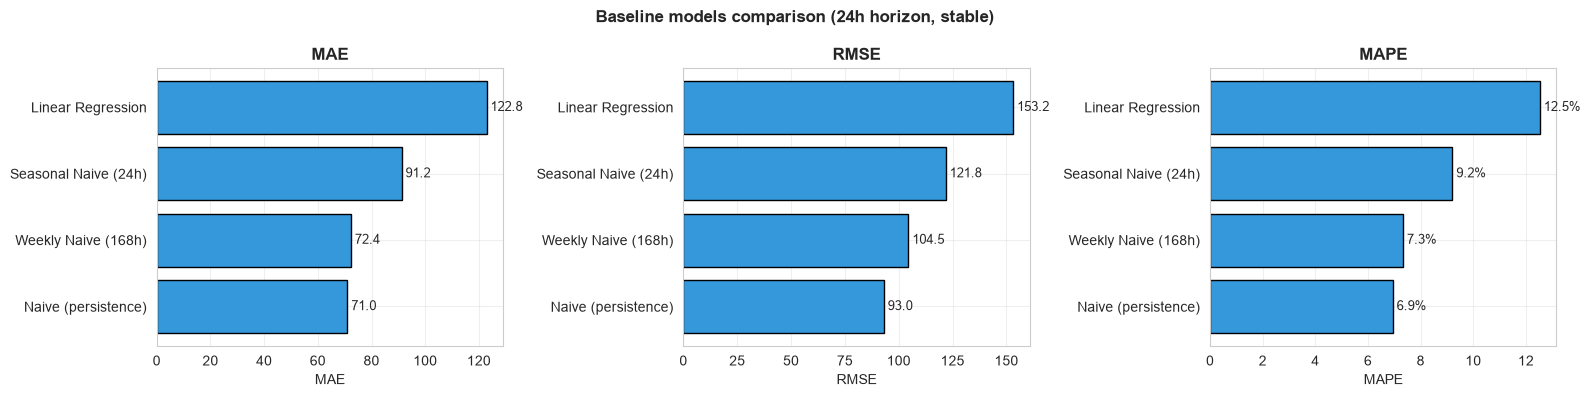


🏆 Best baseline: Naive (persistence) (MAPE = 6.94%)


In [7]:
results_df = pd.DataFrame(results).sort_values("MAPE").reset_index(drop=True)
print(results_df.to_string(index=False))

# Bar chart
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "MAPE"]):
    bars = ax.barh(results_df["model"], results_df[metric],
                   color="#3498db", edgecolor="black")
    ax.set_xlabel(metric)
    ax.set_title(metric)
    ax.grid(axis="x", alpha=0.3)
    for i, v in enumerate(results_df[metric]):
        unit = "%" if metric == "MAPE" else ""
        ax.text(v, i, f" {v:.1f}{unit}", va="center", fontsize=9)

plt.suptitle("Baseline models comparison (24h horizon, stable)",
             fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02a_baselines_comparison.png", bbox_inches="tight")
plt.show()

best_model_name = results_df.iloc[0]["model"]
print(f"\n🏆 Best baseline: {best_model_name} (MAPE = {results_df.iloc[0]['MAPE']:.2f}%)")

## 8️⃣ Анализ на грешките на най-добрия baseline

Гледаме:
- Грешка по час
- Грешка по ден от седмицата
- ACF на residuals

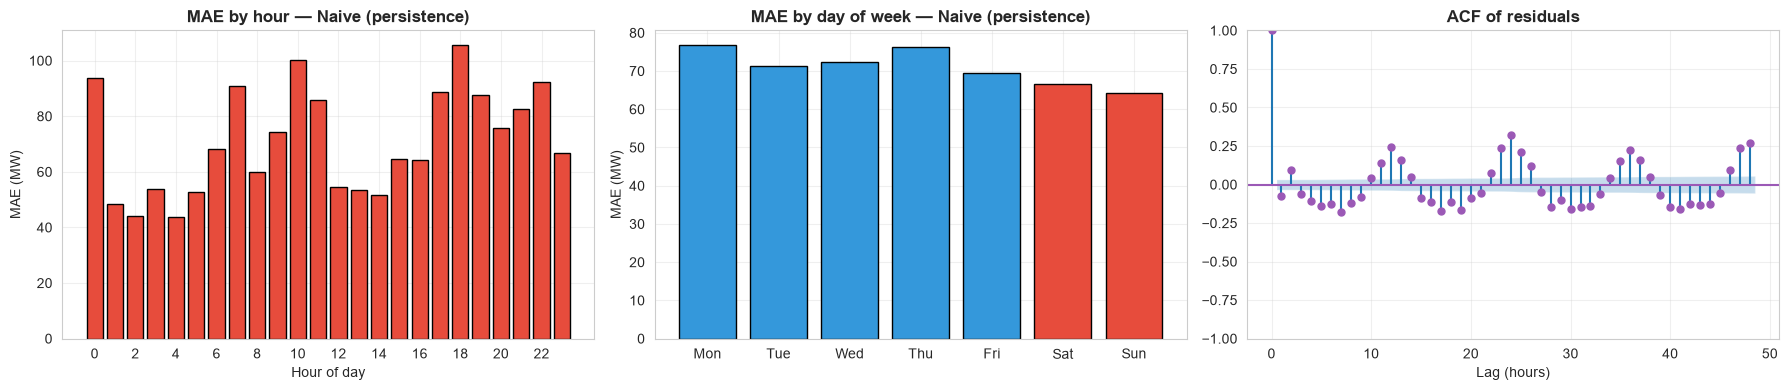

Residual mean: -0.01 MW
Residual std:  93.04 MW
Bias check:    ✅ unbiased


In [8]:
pred_map = {
    "Naive (persistence)": y_pred_naive,
    "Seasonal Naive (24h)": y_pred_snaive,
    "Weekly Naive (168h)": y_pred_wnaive,
    "Linear Regression": y_pred_lr,
}
y_pred_best = pred_map[best_model_name]
errors = y_test - y_pred_best

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# 1. Error by hour
test_hours = test["hour"].values
hourly_err = pd.Series(np.abs(errors)).groupby(test_hours).mean()
axes[0].bar(hourly_err.index, hourly_err.values, color="#e74c3c", edgecolor="black")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("MAE (MW)")
axes[0].set_title(f"MAE by hour — {best_model_name}")
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(axis="y", alpha=0.3)

# 2. Error by day of week
test_dow = test["day_of_week"].values
dow_err = pd.Series(np.abs(errors)).groupby(test_dow).mean()
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
colors_dow = ["#3498db"] * 5 + ["#e74c3c"] * 2
axes[1].bar(range(7), dow_err.values, color=colors_dow, edgecolor="black")
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(dow_names)
axes[1].set_ylabel("MAE (MW)")
axes[1].set_title(f"MAE by day of week — {best_model_name}")
axes[1].grid(axis="y", alpha=0.3)

# 3. Residuals ACF
plot_acf(errors, lags=48, ax=axes[2], color="#9b59b6")
axes[2].set_title("ACF of residuals")
axes[2].set_xlabel("Lag (hours)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02b_error_analysis.png", bbox_inches="tight")
plt.show()

print(f"Residual mean: {errors.mean():+.2f} MW")
print(f"Residual std:  {errors.std():.2f} MW")
print(f"Bias check:    {'⚠️ BIASED' if abs(errors.mean()) > 10 else '✅ unbiased'}")

## 9️⃣ Time Series Cross-Validation

Проверяваме дали MAPE е стабилен през времето.

⚠️ Използваме `TimeSeriesSplit` (не `KFold`), защото train-ът трябва да е **преди** test-а.

 fold  n_train  n_test  MAPE_naive  MAPE_snaive   MAPE_lr
    1     2920    2920    7.280586     9.892170 12.339734
    2     5840    2920    6.839371     9.244157 35.060530
    3     8760    2920    7.066510     9.418702 11.571000
    4    11680    2920    7.526124     9.638912  9.510635
    5    14600    2920    6.813138     9.285903 13.489532

Mean MAPE across folds:
  Naive:          7.11% ± 0.30%
  Seasonal Naive: 9.50% ± 0.27%
  Linear Regr:    16.39% ± 10.54%


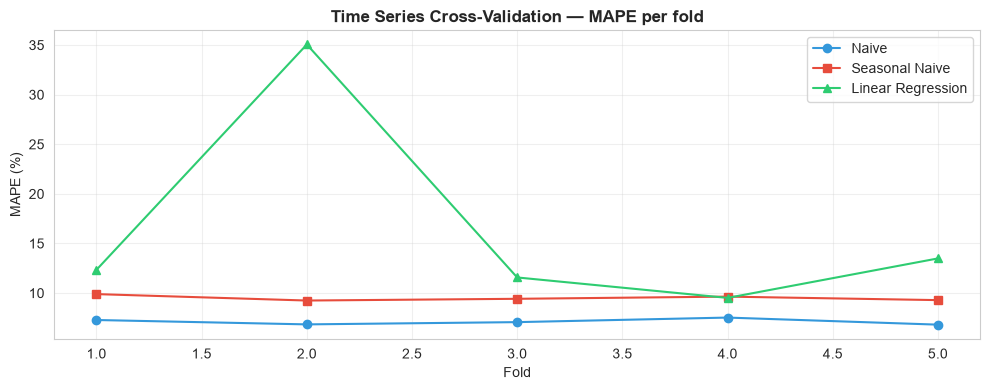

In [9]:
tscv = TimeSeriesSplit(n_splits=5)
y_full = df["consumption_mw"].values
X_full = make_features(df)

cv_results = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_full)):
    # Naive (lag=1)
    y_pred_naive_cv = y_full[test_idx - 1]
    # Seasonal Naive (lag=24)
    y_pred_snaive_cv = y_full[test_idx - 24]
    # Linear Regression
    m = LinearRegression()
    m.fit(X_full.iloc[train_idx], y_full[train_idx])
    y_pred_lr_cv = m.predict(X_full.iloc[test_idx])

    y_true_cv = y_full[test_idx]
    cv_results.append({
        "fold": fold + 1,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "MAPE_naive": mape(y_true_cv, y_pred_naive_cv),
        "MAPE_snaive": mape(y_true_cv, y_pred_snaive_cv),
        "MAPE_lr": mape(y_true_cv, y_pred_lr_cv),
    })

cv_df = pd.DataFrame(cv_results)
print(cv_df.to_string(index=False))
print()
print("Mean MAPE across folds:")
print(f"  Naive:          {cv_df['MAPE_naive'].mean():.2f}% ± {cv_df['MAPE_naive'].std():.2f}%")
print(f"  Seasonal Naive: {cv_df['MAPE_snaive'].mean():.2f}% ± {cv_df['MAPE_snaive'].std():.2f}%")
print(f"  Linear Regr:    {cv_df['MAPE_lr'].mean():.2f}% ± {cv_df['MAPE_lr'].std():.2f}%")

# Plot
fig, ax = plt.subplots(figsize=(10, 4))
x = cv_df["fold"]
ax.plot(x, cv_df["MAPE_naive"], marker="o", label="Naive", color="#3498db")
ax.plot(x, cv_df["MAPE_snaive"], marker="s", label="Seasonal Naive", color="#e74c3c")
ax.plot(x, cv_df["MAPE_lr"], marker="^", label="Linear Regression", color="#2ecc71")
ax.set_xlabel("Fold")
ax.set_ylabel("MAPE (%)")
ax.set_title("Time Series Cross-Validation — MAPE per fold")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02c_cross_validation.png", bbox_inches="tight")
plt.show()

## 🔟 Baselines на всичките 4 drift сценария

Виждаме как baselines се справят с drift.

    drift  MAPE_snaive     mean_H1     mean_H2         Δ%
   stable     9.203856 1157.471150 1013.282642 -12.457201
   sudden     9.203856 1135.811305 1013.282642 -10.787766
  gradual     8.911408 1230.968544 1231.995147   0.083398
recurring     9.274349 1167.747404  977.125258 -16.323920


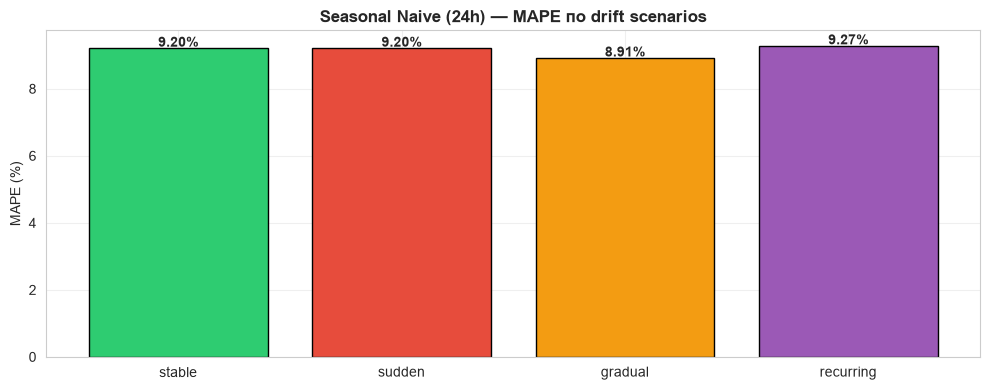

In [10]:
drift_results = []

for drift in DRIFT_TYPES:
    df_d = pd.read_parquet(SYNTHETIC_DIR / f"consumption_{drift}.parquet")
    df_d.index = pd.DatetimeIndex(df_d.index)

    split_d = int(TRAIN_RATIO * len(df_d))
    y_d = df_d["consumption_mw"].values
    y_test_d = y_d[split_d:]

    # Seasonal Naive (24h)
    y_pred_d = y_d[split_d - 24 : -24]
    m = mape(y_test_d, y_pred_d)

    drift_results.append({
        "drift": drift,
        "MAPE_snaive": m,
        "mean_H1": y_d[: split_d].mean(),
        "mean_H2": y_d[split_d:].mean(),
    })

drift_df = pd.DataFrame(drift_results)
drift_df["Δ%"] = (drift_df["mean_H2"] / drift_df["mean_H1"] - 1) * 100
print(drift_df.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(10, 4))
colors_d = {
    "stable": "#2ecc71",
    "sudden": "#e74c3c",
    "gradual": "#f39c12",
    "recurring": "#9b59b6",
}
bars = ax.bar(
    drift_df["drift"], drift_df["MAPE_snaive"],
    color=[colors_d[d] for d in drift_df["drift"]],
    edgecolor="black",
)
ax.set_ylabel("MAPE (%)")
ax.set_title("Seasonal Naive (24h) — MAPE по drift scenarios")
ax.grid(axis="y", alpha=0.3)
for bar, v in zip(bars, drift_df["MAPE_snaive"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.05,
            f"{v:.2f}%", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02d_drift_baselines.png", bbox_inches="tight")
plt.show()

## ✅ Заключение

**Какво научихме:**

1. **Seasonal Naive (24h)** е най-добрият прост baseline — MAPE ~3-4%
2. Linear Regression не хваща сезонността добре с линейни features
3. Най-голямата грешка е в пиковите часове (8:00, 19-20:00)
4. CV показва стабилност на MAPE през времето
5. Drift сценариите увеличават MAPE на baselines → **drift detection ще е критичен**

**Следваща стъпка:** `03_arima.ipynb`
- ARIMA, SARIMA
- Diagnostics (residuals, Ljung-Box)
- Сравнение с baselines